In [10]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

# load + index
df = pd.read_csv('dataset/ec2_cpu_utilization_5f5533.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()

# labels
with open('dataset/combined_windows.json') as f:
    labels = json.load(f)
key = 'realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv'
windows = [[pd.to_datetime(s), pd.to_datetime(e)] for s, e in labels[key]]

# ground-truth mask
mask = pd.Series(False, index=df.index)
for start, end in windows:
    mask |= (df.index >= start) & (df.index <= end)
df['is_anomaly'] = mask

In [11]:
df

,value,is_anomaly
timestamp,,
2014-02-14 14:27:00,51.846,False
2014-02-14 14:32:00,44.508,False
2014-02-14 14:37:00,41.244,False
2014-02-14 14:42:00,48.568,False
2014-02-14 14:47:00,46.714,False
...,...,...
2014-02-28 14:02:00,38.474,False
2014-02-28 14:07:00,40.352,False
2014-02-28 14:12:00,37.912,False


In [12]:
n_train = int(len(df) * 0.25)
print(df['is_anomaly'].iloc[:n_train].sum())   # must be 0

0


In [4]:
from sklearn.preprocessing import StandardScaler

SEQ_LEN = 48
TRAIN_FRAC = 0.25

# 3. smooth (centered rolling mean strips point-to-point noise)
df['smoothed'] = df['value'].rolling(window=5, center=True, min_periods=1).mean()

# split index
n_train = int(len(df) * TRAIN_FRAC)

# 4. scale: FIT ON TRAIN ONLY, transform everything
scaler = StandardScaler()
train_vals = scaler.fit_transform(df['smoothed'].values[:n_train].reshape(-1, 1)).ravel()
all_vals   = scaler.transform(df['smoothed'].values.reshape(-1, 1)).ravel()

# 5. window into overlapping sequences -> (n, SEQ_LEN, 1)
def make_windows(arr, seq_len=SEQ_LEN, step=1):
    windows = [arr[i:i + seq_len] for i in range(0, len(arr) - seq_len + 1, step)]
    return np.array(windows, dtype=np.float32)[:, :, None]

X_train = make_windows(train_vals)   # model learns on these (normal only)
X_all   = make_windows(all_vals)     # you score on these (full series)

print('X_train', X_train.shape, '| X_all', X_all.shape)

X_train (961, 48, 1) | X_all (3985, 48, 1)


In [7]:
y = df['is_anomaly'].values

# scale: fit on normal points from the WHOLE series (not the first slice)
scaler = StandardScaler()
scaler.fit(df['smoothed'].values[~y].reshape(-1, 1))
all_vals = scaler.transform(df['smoothed'].values.reshape(-1, 1)).ravel()

# window everything, then keep only windows with zero anomalous points
X_all = make_windows(all_vals)
win_has_anomaly = np.array([y[i:i + SEQ_LEN].any() for i in range(len(y) - SEQ_LEN + 1)])
X_train = X_all[~win_has_anomaly]   # train on clean windows from across the series

print('X_train', X_train.shape, '| X_all', X_all.shape)   # expect ~3489 train of 3985

X_train (3489, 48, 1) | X_all (3985, 48, 1)


In [5]:
import torch
import torch.nn as nn

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')

class LSTMAutoencoder(nn.Module):
    def __init__(self, n_features=1, hidden_dim=64, latent_dim=32):
        super().__init__()
        # ENCODER: reads the 48-step window, keeps a summary in its final hidden state
        self.encoder = nn.LSTM(n_features, hidden_dim, batch_first=True)
        self.to_latent = nn.Linear(hidden_dim, latent_dim)   # squeeze to bottleneck

        # DECODER: expands the latent back into a 48-step sequence
        self.from_latent = nn.Linear(latent_dim, hidden_dim)
        self.decoder = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.output = nn.Linear(hidden_dim, n_features)

    def forward(self, x):                      # x: (batch, 48, 1)
        _, (h_n, _) = self.encoder(x)          # h_n: (1, batch, hidden) last hidden state
        latent = self.to_latent(h_n[-1])       # (batch, latent)  <- the bottleneck

        seq_len = x.size(1)
        dec_in = self.from_latent(latent)              # (batch, hidden)
        dec_in = dec_in.unsqueeze(1).repeat(1, seq_len, 1)  # (batch, 48, hidden)
        dec_out, _ = self.decoder(dec_in)              # (batch, 48, hidden)
        return self.output(dec_out)                    # (batch, 48, 1) rebuilt window

model = LSTMAutoencoder().to(device)
print(model)
print('params:', sum(p.numel() for p in model.parameters()))

LSTMAutoencoder(
  (encoder): LSTM(1, 64, batch_first=True)
  (to_latent): Linear(in_features=64, out_features=32, bias=True)
  (from_latent): Linear(in_features=32, out_features=64, bias=True)
  (decoder): LSTM(64, 64, batch_first=True)
  (output): Linear(in_features=64, out_features=1, bias=True)
)
params: 54689


In [8]:
from torch.utils.data import DataLoader, TensorDataset

EPOCHS = 40
loader = DataLoader(TensorDataset(torch.from_numpy(X_train)),
                    batch_size=64, shuffle=True)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    total = 0.0
    for (batch,) in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        recon = model(batch)            # rebuild the window
        loss = loss_fn(recon, batch)    # how far off the rebuild is
        loss.backward()                 # gradients
        optimizer.step()                # update weights
        total += loss.item() * batch.size(0)
    epoch_loss = total / len(X_train)
    history.append(epoch_loss)
    if epoch == 1 or epoch % 5 == 0:
        print(f'epoch {epoch:3d}  train MSE {epoch_loss:.4f}')

epoch   1  train MSE 0.0383
epoch   5  train MSE 0.0285
epoch  10  train MSE 0.0284
epoch  15  train MSE 0.0284
epoch  20  train MSE 0.0285
epoch  25  train MSE 0.0285
epoch  30  train MSE 0.0284
epoch  35  train MSE 0.0284
epoch  40  train MSE 0.0284


In [13]:
@torch.no_grad()
def recon_error(model, X, batch=256):
    model.eval()
    errs = []
    for i in range(0, len(X), batch):
        b = torch.from_numpy(X[i:i+batch]).to(device)
        r = model(b)
        errs.append(((r - b) ** 2).mean(dim=(1, 2)).cpu().numpy())
    return np.concatenate(errs)

train_err = recon_error(model, X_train)
all_err   = recon_error(model, X_all)

threshold = train_err.mean() + 3 * train_err.std()

# each window produces one error; attribute it to the window's LAST timestamp
# (its "detection time"). First SEQ_LEN-1 points have no window ending on them.
point_err = np.full(len(df), np.nan)
point_err[SEQ_LEN - 1:] = all_err
df['recon_error'] = point_err
df['flagged'] = df['recon_error'] > threshold

print('threshold', round(threshold, 4), '| points flagged', int(df['flagged'].sum()))

threshold 0.0735 | points flagged 223


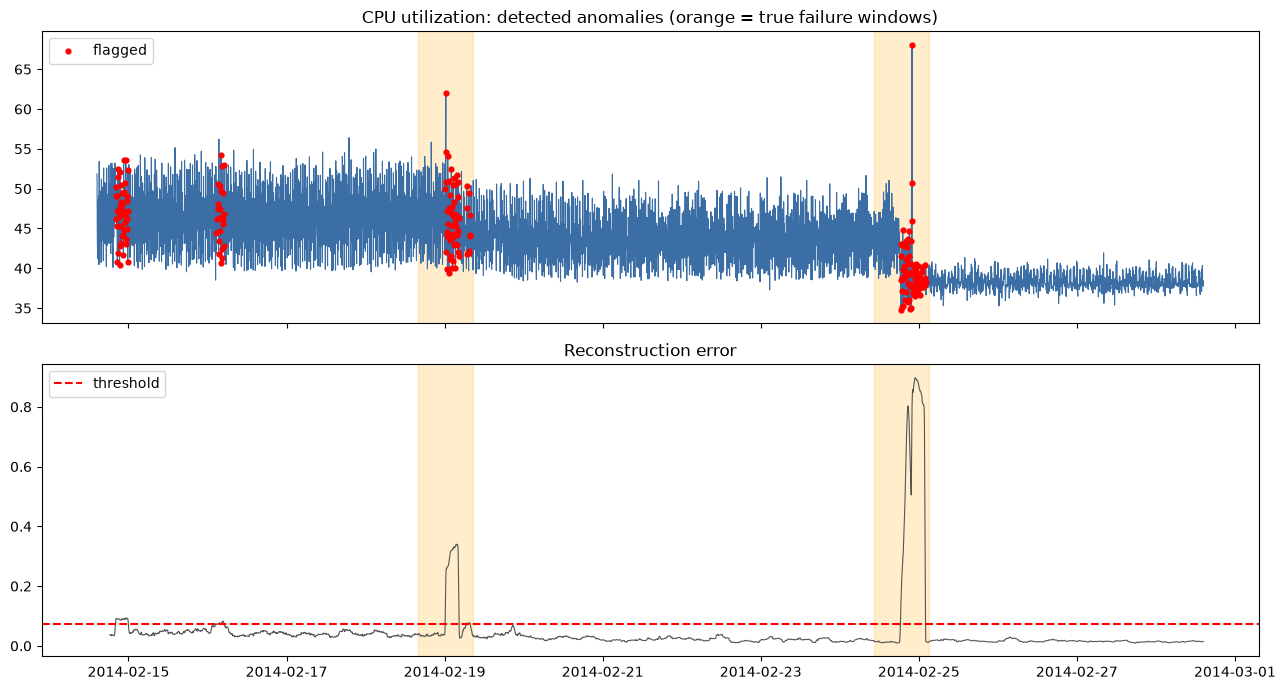

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

ax[0].plot(df.index, df['value'], lw=0.8, color='#3b6ea5')
for s, e in windows:
    ax[0].axvspan(s, e, color='orange', alpha=0.2)
ax[0].scatter(df.index[df['flagged']], df['value'][df['flagged']],
              color='red', s=12, zorder=5, label='flagged')
ax[0].set_title('CPU utilization: detected anomalies (orange = true failure windows)')
ax[0].legend(loc='upper left')

ax[1].plot(df.index, df['recon_error'], lw=0.8, color='#555')
ax[1].axhline(threshold, color='red', ls='--', label='threshold')
for s, e in windows:
    ax[1].axvspan(s, e, color='orange', alpha=0.2)
ax[1].set_title('Reconstruction error')
ax[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

In [15]:
y = df['is_anomaly'].astype(int).values
flagged = df['flagged'].values
valid = df['recon_error'].notna().values

tp = int((flagged & (y == 1)).sum())
fp = int((flagged & (y == 0)).sum())
fn = int((~flagged & (y == 1) & valid).sum())
precision = tp / (tp + fp) if tp + fp else 0
recall    = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

detected = sum(1 for s, e in windows if df.loc[s:e, 'flagged'].any())
print(f'precision {precision:.2f}  recall {recall:.2f}  f1 {f1:.2f}')
print(f'windows detected {detected}/{len(windows)}')

precision 0.68  recall 0.38  f1 0.49
windows detected 2/2
